# 2. Data Cleaning and Feature Preparation

Objectives:

- verify the four-year hourly timeline;
- audit missingness and continuous gaps;
- apply only defensible validity rules;
- retain plausible high-pollution episodes;
- engineer lag, cyclic, and target features using **Hanoi local time**;
- save model-ready datasets for fair feature-ablation experiments.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INTERIM_DIR = Path("../data/interim")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

INTERIM_PATH = (
    INTERIM_DIR /
    "hanoi_openmeteo_aq_weather_hourly_2022_2026.pkl"
)

df_merged = pd.read_pickle(INTERIM_PATH)

## 1. Structural checks

In [5]:
print("Shape:", df_merged.shape)
print("Columns:", df_merged.columns.tolist())

print(
    "Local period:",
    df_merged["timestamp_local"].min(),
    "->",
    df_merged["timestamp_local"].max(),
)

print(
    "Duplicate local timestamps:",
    df_merged["timestamp_local"].duplicated().sum(),
)

print(
    "Hourly continuity:",
    df_merged["timestamp_local"]
    .diff()
    .dropna()
    .eq(pd.Timedelta(hours=1))
    .all(),
)

Shape: (35064, 11)
Columns: ['timestamp_local', 'timestamp_utc', 'pm25', 'pm10', 'no2', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'surface_pressure', 'wind_speed_10m', 'wind_direction_10m']
Local period: 2022-09-01 00:00:00+07:00 -> 2026-08-31 23:00:00+07:00
Duplicate local timestamps: 0
Hourly continuity: True


/var/folders/sb/pmlt6jxs48zgnsjrc491m_s80000gn/T/ipykernel_86502/1486908147.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  .eq(pd.Timedelta(hours=1))


In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df_merged.isna().sum(),
    "missing_pct": (
        df_merged.isna()
        .mean()
        .mul(100)
        .round(3)
    ),
})

missing_summary

,missing_count,missing_pct
timestamp_local,0,0.0
timestamp_utc,0,0.0
pm25,0,0.0
pm10,0,0.0
no2,0,0.0
temperature_2m,0,0.0
relative_humidity_2m,0,0.0
precipitation,0,0.0
surface_pressure,0,0.0
wind_speed_10m,0,0.0


## 2. Gap analysis

The previous one-year OpenAQ dataset contained sensor outages. The four-year Open-Meteo dataset is expected to be much more complete, but the same gap audit is retained so the pipeline remains explicit and reproducible.

In [7]:
def summarize_missing_gaps(df, column, time_col="timestamp_local"):
    is_missing = df[column].isna()

    if not is_missing.any():
        return pd.DataFrame(
            columns=["start", "end", "length_hours"]
        )

    gap_id = (is_missing != is_missing.shift()).cumsum()

    return (
        df.loc[is_missing]
        .groupby(gap_id[is_missing])
        .agg(
            start=(time_col, "min"),
            end=(time_col, "max"),
            length_hours=(time_col, "size"),
        )
        .reset_index(drop=True)
    )

pollutants = ["pm25", "pm10", "no2"]

gap_tables = {
    col: summarize_missing_gaps(df_merged, col)
    for col in pollutants
}

gap_summary_records = []

for col, gaps in gap_tables.items():
    gap_summary_records.append({
        "variable": col,
        "missing_hours": int(df_merged[col].isna().sum()),
        "number_of_gaps": int(len(gaps)),
        "median_gap_hours": (
            float(gaps["length_hours"].median())
            if len(gaps) else 0
        ),
        "longest_gap_hours": (
            int(gaps["length_hours"].max())
            if len(gaps) else 0
        ),
    })

gap_summary = pd.DataFrame(gap_summary_records)
gap_summary

,variable,missing_hours,number_of_gaps,median_gap_hours,longest_gap_hours
0,pm25,0,0,0,0
1,pm10,0,0,0,0
2,no2,0,0,0,0


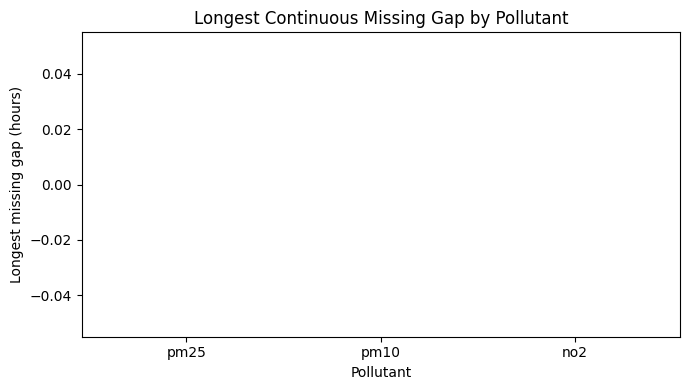

In [8]:
plt.figure(figsize=(7, 4))
plt.bar(
    gap_summary["variable"],
    gap_summary["longest_gap_hours"],
)
plt.xlabel("Pollutant")
plt.ylabel("Longest missing gap (hours)")
plt.title("Longest Continuous Missing Gap by Pollutant")
plt.tight_layout()
plt.show()

## 3. Validity checks

Only values that are physically impossible under the variable definition are converted to missing. Statistical extremes are **not** removed merely because they exceed an IQR threshold.

This is deliberately conservative: high PM2.5 values may represent genuine severe-pollution episodes.

In [9]:
df_clean = df_merged.copy()

# Pollutant concentrations cannot be negative.
for col in ["pm25", "pm10", "no2"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

# Basic physical sanity rules for weather variables.
df_clean.loc[
    ~df_clean["relative_humidity_2m"].between(0, 100),
    "relative_humidity_2m"
] = np.nan

for col in ["precipitation", "wind_speed_10m"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

print("Missingness after validity checks:")
display(df_clean.isna().sum().to_frame("missing_count"))

Missingness after validity checks:


,missing_count
timestamp_local,0
timestamp_utc,0
pm25,0
pm10,0
no2,0
temperature_2m,0
relative_humidity_2m,0
precipitation,0
surface_pressure,0
wind_speed_10m,0


## 4. Create target and candidate lag features

The forecasting target is **PM2.5 six hours ahead**.

Because the full hourly timeline is preserved before shifting, `lag1` means exactly one clock hour earlier, `lag24` means exactly one day earlier, and the target corresponds exactly to `t+6`.

In [10]:
df_model = df_clean.copy()

FORECAST_HOURS = 6
CANDIDATE_LAGS = [1, 2, 3, 6, 12, 18, 24]

for lag in CANDIDATE_LAGS:
    df_model[f"pm25_lag{lag}"] = (
        df_model["pm25"].shift(lag)
    )

df_model["pm25_t_plus_6"] = (
    df_model["pm25"].shift(-FORECAST_HOURS)
)

target_check = df_model["pm25_t_plus_6"].equals(
    df_model["pm25"].shift(-FORECAST_HOURS)
)

print("6-hour target alignment:", target_check)

6-hour target alignment: True


## 5. Cyclic features from Hanoi local time

`timestamp_local` is already timezone-aware `Asia/Ho_Chi_Minh`. Therefore the hour, day-of-week, and month features below refer to the actual Hanoi local calendar rather than UTC.

Cyclic encoding prevents artificial discontinuities such as hour 23 being treated as far from hour 0.

In [11]:
# Wind direction
wind_rad = np.deg2rad(df_model["wind_direction_10m"])
df_model["wind_dir_sin"] = np.sin(wind_rad)
df_model["wind_dir_cos"] = np.cos(wind_rad)

# Local calendar components
hour = df_model["timestamp_local"].dt.hour
dow = df_model["timestamp_local"].dt.dayofweek
month = df_model["timestamp_local"].dt.month

df_model["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df_model["hour_cos"] = np.cos(2 * np.pi * hour / 24)

df_model["dow_sin"] = np.sin(2 * np.pi * dow / 7)
df_model["dow_cos"] = np.cos(2 * np.pi * dow / 7)

df_model["month_sin"] = np.sin(
    2 * np.pi * (month - 1) / 12
)
df_model["month_cos"] = np.cos(
    2 * np.pi * (month - 1) / 12
)

df_model[
    [
        "timestamp_local",
        "hour_sin",
        "hour_cos",
        "month_sin",
        "month_cos",
    ]
].head()

,timestamp_local,hour_sin,hour_cos,month_sin,month_cos
0,2022-09-01 00:00:00+07:00,0.000000,1.000000,-0.866025,-0.5
1,2022-09-01 01:00:00+07:00,0.258819,0.965926,-0.866025,-0.5
2,2022-09-01 02:00:00+07:00,0.500000,0.866025,-0.866025,-0.5
3,2022-09-01 03:00:00+07:00,0.707107,0.707107,-0.866025,-0.5
4,2022-09-01 04:00:00+07:00,0.866025,0.500000,-0.866025,-0.5


## 6. Design four feature sets

Candidate PM2.5 lags are retained here. Seven PM2.5 lag features are constructed and retained in the Core feature set. Their contribution is evaluated through the model comparison and feature-ablation experiments.

In [12]:
lag_features = [
    f"pm25_lag{lag}"
    for lag in CANDIDATE_LAGS
]

features_history = [
    "pm25",
] + lag_features

weather_time_features = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "surface_pressure",
    "wind_speed_10m",
    "wind_dir_sin",
    "wind_dir_cos",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
]

features_base = (
    features_history
    + weather_time_features
)

features_pm10 = features_base + ["pm10"]

features_full = features_pm10 + ["no2"]

target = "pm25_t_plus_6"

## 7. Create model-ready datasets

Rows are removed only when a variable required by that specific feature set is unavailable. Each saved dataset contains only the timestamp, the predictors required by that experiment, and the target.

In [13]:
timestamp_cols = [
    "timestamp_local",
    "timestamp_utc",
]

def make_model_ready(df, features, target):
    cols = timestamp_cols + features + [target]

    return (
        df
        .dropna(subset=features + [target])
        [cols]
        .copy()
        .sort_values("timestamp_local")
        .reset_index(drop=True)
    )

df_history = make_model_ready(
    df_model,
    features_history,
    target,
)

df_base = make_model_ready(
    df_model,
    features_base,
    target,
)

df_pm10 = make_model_ready(
    df_model,
    features_pm10,
    target,
)

df_full = make_model_ready(
    df_model,
    features_full,
    target,
)

print("History only:", df_history.shape)
print("Base:", df_base.shape)
print("Base + PM10:", df_pm10.shape)
print("Full + PM10 + NO2:", df_full.shape)

History only: (35034, 11)
Base: (35034, 24)
Base + PM10: (35034, 25)
Full + PM10 + NO2: (35034, 26)


In [14]:
print("History columns:")
print(df_history.columns.tolist())

print("\nFull columns:")
print(df_full.columns.tolist())

History columns:
['timestamp_local', 'timestamp_utc', 'pm25', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag6', 'pm25_lag12', 'pm25_lag18', 'pm25_lag24', 'pm25_t_plus_6']

Full columns:
['timestamp_local', 'timestamp_utc', 'pm25', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag6', 'pm25_lag12', 'pm25_lag18', 'pm25_lag24', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'surface_pressure', 'wind_speed_10m', 'wind_dir_sin', 'wind_dir_cos', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'pm10', 'no2', 'pm25_t_plus_6']


## 8. Save processed datasets

In [15]:
df_model.to_pickle(
    PROCESSED_DIR /
    "hanoi_pm25_model_withna_4y.pkl"
)

df_history.to_pickle(
    PROCESSED_DIR /
    "hanoi_pm25_model_history_4y.pkl"
)

df_base.to_pickle(
    PROCESSED_DIR /
    "hanoi_pm25_model_base_4y.pkl"
)

df_pm10.to_pickle(
    PROCESSED_DIR /
    "hanoi_pm25_model_pm10_4y.pkl"
)

df_full.to_pickle(
    PROCESSED_DIR /
    "hanoi_pm25_model_full_4y.pkl"
)

## 9. Cleaning outcome

The four-year pipeline:

- preserves the complete local hourly timeline before feature engineering;
- does not interpolate plausible pollutant values merely to increase sample size;
- retains high PM2.5 episodes unless there is evidence they are physically invalid;
- creates a 6-hour-ahead target and a broader set of candidate lags (`1, 2, 3, 6, 12, 18, 24 h`);
- creates hour/day/month cyclic features from **Hanoi local time**;
- defers lag/feature selection to the validation stage in the modeling notebook.

In [16]:
df_model["pm25"].describe()

count    35064.000000
mean        45.438969
std         27.653881
min          0.300000
25%         26.300000
50%         38.400000
75%         56.800000
max        232.800000
Name: pm25, dtype: float64